In [2]:
from matplotlib import pyplot as plt
import scipy
import numpy as np
from scipy import sparse
import sys
sys.path.insert(0, '..')   # goes from paper_plots/fig_1_compQITE -> repo root
from modules import Hamiltonian as ham
from modules import PauliStrings
from modules import Evolution as evol
from matplotlib.lines import Line2D
import cmcrameri.cm as cmc

In [3]:
color1="#0041FC"
color2="#FC9904"
color3="#7D7548"

In [4]:
def fidelity_pure(psi,phi):
    '''
    input values should be column vectors
    '''
    F=np.abs(psi.conj().T@phi)**2
    return F

In [5]:
HeiQITE = np.load("heisenberg/qite_default/trajectory.npz", allow_pickle=True)
ordQITE = np.load("tfim_ord/qite_default/trajectory.npz", allow_pickle=True)
disQITE = np.load("tfim_disord/qite_default/trajectory.npz", allow_pickle=True)

HeiSpQ = np.load("heisenberg/spqite/trajectory.npz", allow_pickle=True)
ordSpQ = np.load("tfim_ord/spqite/trajectory.npz", allow_pickle=True)
disSpQ = np.load("tfim_disord/spqite/trajectory.npz", allow_pickle=True)

In [6]:
def weight_distribution_over_time(a_array, weights_j, weight_values, normalize=True):
    """
    Build matrix M[t, w] = aggregated |a| at time t for Pauli weight w.
    If normalize=True, each time row is normalized to sum to 1.
    """
    n_steps = a_array.shape[0]
    M = np.zeros((n_steps, len(weight_values)), dtype=float)

    for t_idx in range(n_steps):
        coeffs = np.abs(a_array[t_idx, :, :])  # shape: (Nk, num_paulis)
        for w_idx, w in enumerate(weight_values):
            mask = (weights_j == w)
            if np.any(mask):
                M[t_idx, w_idx] = coeffs[:, mask].sum()

        if normalize:
            row_sum = M[t_idx].sum()
            if row_sum > 0:
                M[t_idx] /= row_sum

    return M

# Models Heatmap

In [7]:
n_qubits = 8
D=6
dt=0.05
H_Hei, H_trot = ham.Heisenberg_PBC(1,8,2,False)
E_Hei,V_Hei = np.linalg.eigh(H_Hei)
GS_Hei = V_Hei[:,0]
# Reconstruct the Pauli-string labels used in QITE so each coefficient index maps to a weight
if np.isreal(H_Hei.data).all() and np.isreal(GS_Hei.data).all():
    _, PD_strings, _ = PauliStrings.real(H_trot, D, n_qubits, PDstr=True)
else:
    _, PD_strings, _ = PauliStrings.general(H_trot, D, n_qubits, PDstr=True)
# Weight for each Pauli index j (same ordering for all trotter pieces)
weights_per_j = np.array([sum(ch != 'I' for ch in pstr) for pstr in PD_strings[0]], dtype=int)
unique_weights = np.arange(weights_per_j.min(), weights_per_j.max() + 1)
a_Hei = HeiSpQ['a']
M_Hei = weight_distribution_over_time(a_Hei, weights_per_j, unique_weights, normalize=True)

H_ord, Htrot = ham.TFIM(1,0.5,8,2,False)
E_ord,V_ord = np.linalg.eigh(H_ord)
GS_ord = V_ord[:,0]
# Reconstruct the Pauli-string labels used in QITE so each coefficient index maps to a weight
if np.isreal(H_ord.data).all() and np.isreal(GS_ord.data).all():
    _, PD_strings, _ = PauliStrings.real(H_trot, D, n_qubits, PDstr=True)
else:
    _, PD_strings, _ = PauliStrings.general(H_trot, D, n_qubits, PDstr=True)
# Weight for each Pauli index j (same ordering for all trotter pieces)
weights_per_j = np.array([sum(ch != 'I' for ch in pstr) for pstr in PD_strings[0]], dtype=int)
unique_weights = np.arange(weights_per_j.min(), weights_per_j.max() + 1)
a_ord = ordSpQ['a']
M_ord = weight_distribution_over_time(a_ord, weights_per_j, unique_weights, normalize=True)


Heisenberg model with PBC and Hamiltonian pieces of locality T=2
Succesfull Troterization
The Trotterization consists of 8 terms with the starting qubit of each piece at [0, 1, 2, 3, 4, 5, 6, 7]


In [8]:
D=4
H_dis, Htrot = ham.TFIM(0.5,1,8,2,False)
E_dis,V_dis = np.linalg.eigh(H_dis)
GS_dis = V_dis[:,0]
print(E_dis[0])
# Reconstruct the Pauli-string labels used in QITE so each coefficient index maps to a weight
if np.isreal(H_dis.data).all() and np.isreal(GS_dis.data).all():
    _, PD_strings, _ = PauliStrings.real(H_trot, D, n_qubits, PDstr=True)
else:
    _, PD_strings, _ = PauliStrings.general(H_trot, D, n_qubits, PDstr=True)
# Weight for each Pauli index j (same ordering for all trotter pieces)
weights_per_j = np.array([sum(ch != 'I' for ch in pstr) for pstr in PD_strings[0]], dtype=int)
unique_weights_dis = np.arange(weights_per_j.min(), weights_per_j.max() + 1)
a_dis = disSpQ['a']
M_dis = weight_distribution_over_time(a_dis, weights_per_j, unique_weights_dis, normalize=True)

-8.509082235140271


In [9]:
plt.figure(figsize=(16, 6))
plt.rcParams.update({
    "text.usetex": True,
})
font = {'family' : 'normal',
        'weight' : 'bold',
        'size'   : 22}

plt.rc('font', **font)

<Figure size 1600x600 with 0 Axes>

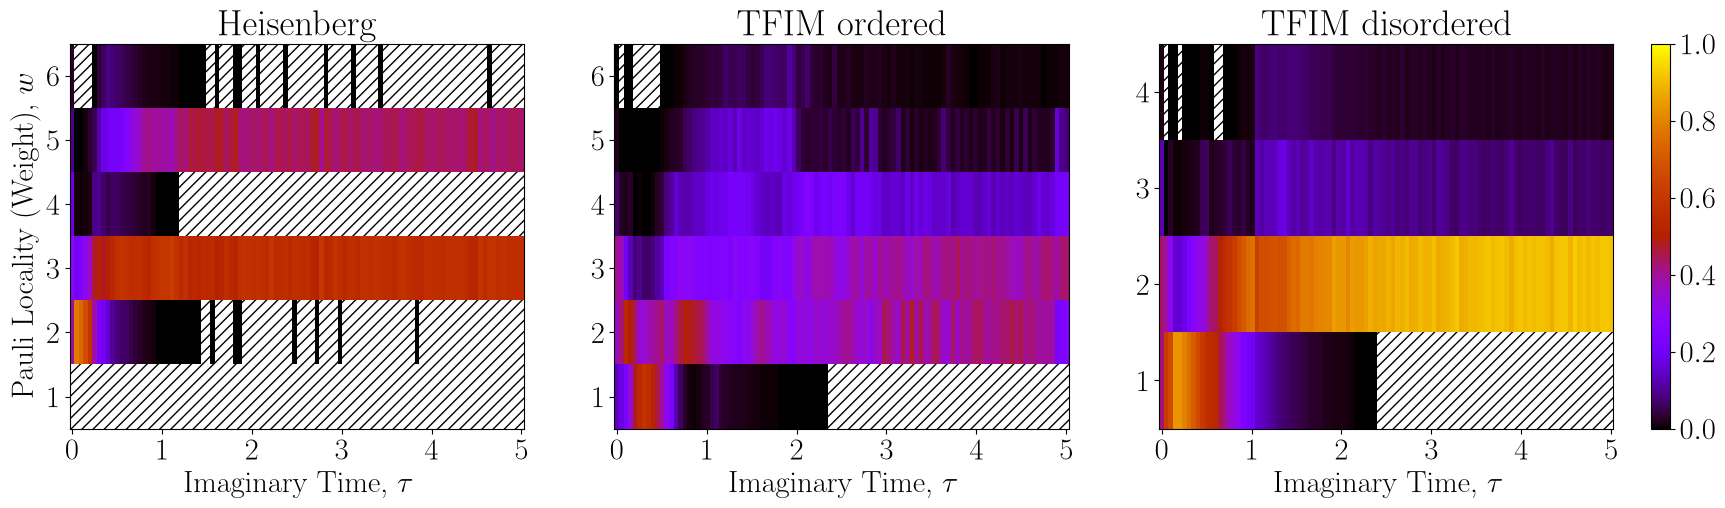

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cmcrameri.cm as cmc

matrices = [M_Hei.T, M_ord.T, M_dis.T]
titles = ["Heisenberg", "TFIM ordered","TFIM disordered"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(24, 5))


plt.rcParams.update({
    "text.usetex": True,
})
font = {'family' : 'normal',
        'weight' : 'bold',
        'size'   : 22}

plt.rc('font', **font)

for ax, M, title in zip(axes, matrices, titles):
    ny, nx = M.shape
    # x coordinates: 100 values spanning 0 -> 5
    x = np.linspace(0, 5, nx)
    dx = x[1] - x[0]
    # y coordinates: 1 -> ny
    y = np.arange(1, ny + 1)
    #print(ny)

    # Heatmap
    im = ax.imshow(
        M,
        aspect="auto",
        origin="lower",
        cmap="gnuplot",
        extent=[
            x[0] - dx / 2,
            x[-1] + dx / 2,
            0.5,
            ny + 0.5
        ],
        vmin=0, vmax=1
    )

    # Hatch zero-valued cells
    for iy, ix in zip(*np.where(M == 0)):
        rect = patches.Rectangle(
            (x[ix] - dx / 2, y[iy] - 0.5),
            dx,
            1,
            facecolor="white",
            edgecolor="black",
            hatch="///",
            linewidth=0
        )
        ax.add_patch(rect)

    # X axis
    ax.set_xticks(np.arange(0, 6, 1))
    ax.set_xlabel("Imaginary Time, $\\tau$")

    # Y axis
    ax.set_yticks(y)
    ax.set_title(title)

# Only label the left y-axis
axes[0].set_ylabel("Pauli Locality (Weight), $w$")


fig.colorbar(
    im,
    ax=axes,
    location="right",
    pad=0.02
)

plt.savefig("heatmap_weight.pdf", bbox_inches='tight', dpi=300)
plt.show()